In [1]:
import numpy as np
import matplotlib.pyplot as plt

(i) First we construct the memory and fix it

In [2]:
N = 400
P = 40

rng = np.random.default_rng()
memory = rng.choice([-1,1], size=(P, N))

(ii) Build the interaction matrix corresponding to the memory accroding to eq (1)

In [3]:
J = np.zeros([N,N])

for i in range(N):
    for j in range(i+1, N):
        J[i, j] = np.sum(memory[:,i]*memory[:,j],axis=0)/N
        J[j, i] = J[i, j]

(iii) Deterministoc dynamics following from eq (2) and (3)

In [4]:
def next_step(old, J):

    h = np.einsum('ij, j->i', J, old)

    new = np.sign(h)
    h0 = np.where(h==0)
    new[h0] = old[h0]

    return new

(iv) function to generate starting state which deviates from memory 1 by some fraction

In [5]:
def generate_start(frac, memory):
    M = int(frac*N)
    indices = rng.choice(np.arange(N), size=M, replace=False)
    start = memory[0].copy()
    start[indices]*=-1

    return start

(v) Check to see if we can go back to the memory we started from in 30 steps

In [6]:
m = np.zeros([3, 30])
fracs = [0.05, 0.25, 0.40]
starts = np.array([generate_start(fracs[0], memory), generate_start(fracs[1], memory), generate_start(fracs[2], memory)])

for i in range(30):
    # define the overalp
    m[0, i] = np.sum(memory[0]*starts[0])/N
    m[1, i] = np.sum(memory[0]*starts[1])/N
    m[2, i] = np.sum(memory[0]*starts[2])/N
    starts[0] = next_step(starts[0], J)
    starts[1] = next_step(starts[1], J)
    starts[2] = next_step(starts[2], J)

(vi) Plotting

+++ Check [m1(0)=1-2f] +++
f=0.05: True
f=0.25: True
f=0.4: True


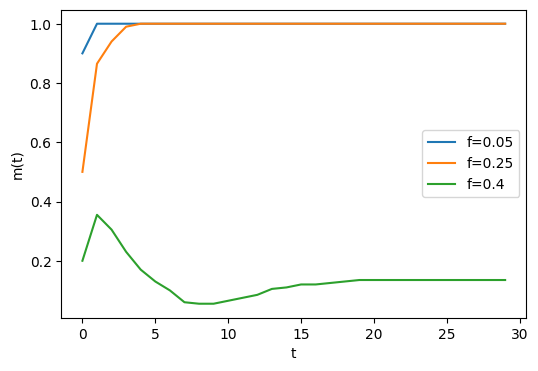

In [7]:
fig, ax = plt.subplots(1,1,figsize=(6, 4))
ax.set_xlabel('t')
ax.set_ylabel('m(t)')

print('+++ Check [m1(0)=1-2f] +++')

for i in range(len(fracs)):
    print(f'f={fracs[i]}: {np.allclose(m[i,0],1-2*fracs[i])}')
    ax.plot(m[i], label=f'f={fracs[i]}')

ax.legend();

So for lower fractions we end up in the same memory we started close too, but not for higher starting deviations

In [25]:
def stochastic_next_step(old, J, T):
    
    h = np.einsum('ij, j->i', J, old)

    prob = 1/(1+np.exp(-2*h/T))
    r = rng.uniform(low=0, high=1, size=len(old))
    new = np.ones(len(old))
    flip = np.where(r>prob)
    new[flip]*=-1

    return new

In [10]:
start = generate_start(0.05, memory)
starts = np.array([start, start, start])
m = np.zeros([3, 40])
temps = [0.1, 0.5, 1]

for i in range(40):
    m[0, i] = np.sum(memory[0]*starts[0])/N
    m[1, i] = np.sum(memory[0]*starts[1])/N
    m[2, i] = np.sum(memory[0]*starts[2])/N
    starts[0] = stochastic_next_step(starts[0], J, temps[0])
    starts[1] = stochastic_next_step(starts[1], J, temps[1])
    starts[2] = stochastic_next_step(starts[2], J, temps[2])

0.9


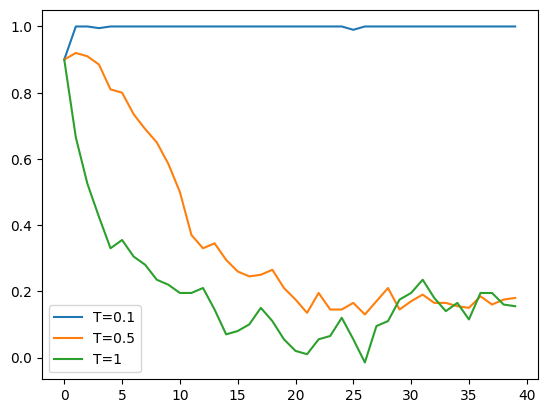

In [11]:
plt.plot(m[0], label=f'T={temps[0]}')
plt.plot(m[1], label=f'T={temps[1]}')
plt.plot(m[2], label=f'T={temps[2]}')
plt.legend()

print(m[0,0])

In [47]:
def stuff(alpha):
    P = int(alpha*N)
    memory = rng.choice([-1, 1], size=(P, N))
    J = np.zeros([N, N])

    for i in range(N):
        for j in range(i+1, N):
            J[i, j] = np.sum(memory[:, i]*memory[:, j], axis=0)/N
            J[j, i] = J[i, j]

    start = generate_start(0.05, memory)
    temps = np.linspace(0.1, 1, 50)
    
    starts = np.tile(start, (len(temps),1))
    m = np.zeros([len(temps), 40])

    for i in range(len(temps)):
        for j in range(40):
            m[i, j] = np.sum(memory[0]*starts[i])/N
            starts[i] = stochastic_next_step(starts[i], J, temps[i])

    return np.mean(m[:, 30:], axis=1)


heat = np.zeros((50, 50))
alpha = np.linspace(0.01, 1, 50)
for i in range(50):
    heat[i] = stuff(alpha[i])

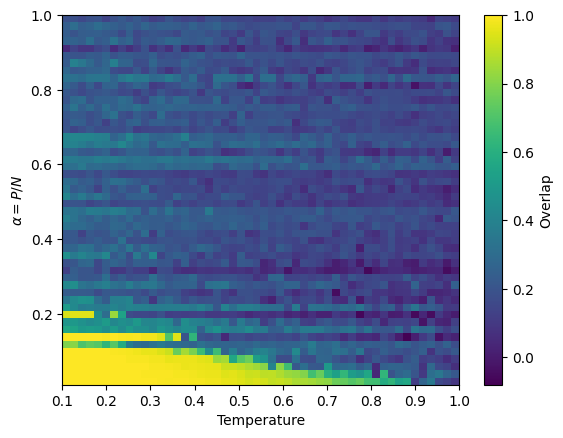

In [54]:
temps = np.linspace(0.1, 1, 50)

plt.imshow(heat,origin="lower",aspect="auto",extent=[temps[0], temps[-1], alpha[0], alpha[-1]])

plt.xlabel("Temperature")
plt.ylabel(r"$\alpha=P/N$")
plt.colorbar(label="Overlap")
plt.show()